# BÀI THỰC HÀNH LAB 1: KHAI PHÁ DỮ LIỆU
- **Học phần:** Khai phá dữ liệu (Data Mining)
- **Họ và tên sinh viên:** Vi Duy Đoàn
- **Mã số sinh viên (MSSV):** 6451071020
- **Lớp:** Khai phá dữ liệu
- **Bài 3:** Tiền xử lý dữ liệu chuỗi thời gian cảm biến môi trường (Bài 2 Trang 30)

---

## Câu 1 (a): Đọc tập tin dữ liệu và Gán tên cột
**Yêu cầu:** Đọc file `tb_tracking.xlsx` (`header=None`) và gán tiêu đề cột theo đúng thứ tự: `['id', 'device_id', 'co_level', 'humidity', 'temperature', 'time']`. Hiển thị `df.head()`.

In [1]:
print("Vi Duy Đoàn - 6451071020")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# 1. Đọc file tb_tracking.xlsx không có tiêu đề cột (header=None)
file_path = 'tb_tracking.xlsx'
df = pd.read_excel(file_path, header=None)

# 2. Gán tiêu đề các cột theo đúng thứ tự yêu cầu
column_names = ['id', 'device_id', 'co_level', 'humidity', 'temperature', 'time']
df.columns = column_names

# 3. Hiển thị 5 dòng đầu tiên và thông tin tổng quát
print("=== 5 DÒNG ĐẦU TIÊN CỦA BẢNG DỮ LIỆU CẢM BIẾN (df.head()) ===")
display(df.head())

print("\n=== THÔNG TIN CẤU TRÚC VÀ KIỂU DỮ LIỆU BAN ĐẦU (df.info()) ===")
df.info()


Vi Duy Đoàn - 6451071020


=== 5 DÒNG ĐẦU TIÊN CỦA BẢNG DỮ LIỆU CẢM BIẾN (df.head()) ===


,id,device_id,co_level,humidity,temperature,time
0,1,DEV_03,0.351,65.7,22.7,2018-01-01 00:00:00
1,2,DEV_01,0.415,65.0,22.2,2018-01-01 00:30:00
2,3,DEV_03,0.619,63.3,22.2,2018-01-01 01:00:00
3,4,DEV_03,0.529,60.7,25.5,2018-01-01 01:30:00
4,5,DEV_01,0.474,61.2,25.2,2018-01-01 02:00:00



=== THÔNG TIN CẤU TRÚC VÀ KIỂU DỮ LIỆU BAN ĐẦU (df.info()) ===
<class 'pandas.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           240 non-null    int64  
 1   device_id    240 non-null    str    
 2   co_level     240 non-null    float64
 3   humidity     240 non-null    float64
 4   temperature  240 non-null    float64
 5   time         240 non-null    str    
dtypes: float64(3), int64(1), str(2)
memory usage: 11.4 KB


### Nhận xét Câu 1 (a):
1. **Mục đích bài toán:** Dữ liệu môi trường nhà xưởng ghi nhận các chỉ số vật lý quan trọng: nồng độ khí CO (`co_level`), độ ẩm (`humidity`), nhiệt độ (`temperature`) theo các mốc thời gian (`time`) từ nhiều trạm thiết bị đo (`device_id`).
2. **Xử lý tiêu đề cột:** File Excel ban đầu không chứa hàng tiêu đề (`header=None`). Thao tác gán nhãn danh sách `['id', 'device_id', 'co_level', 'humidity', 'temperature', 'time']` giúp chuẩn hóa lược đồ dữ liệu, làm rõ ý nghĩa của từng biến phục vụ các bước xử lý và phân tích tiếp theo.
3. **Quan sát ban đầu:** Các giá trị cảm biến đều có kiểu số thực (`float64`), cột định danh thiết bị ở dạng chuỗi, và cột thời gian ghi nhận các thời điểm đo đạc liên tục.

## Câu 2 (b): Chuyển đổi định dạng thời gian và Lọc dữ liệu chuẩn xác
**Yêu cầu:** Chuyển cột `time` về kiểu `datetime`. Lọc và giữ lại các dữ liệu từ ngày `03/01/2018` (`2018-01-03`) trở đi, loại bỏ dữ liệu trước đó. Hiển thị thông tin sau khi lọc.

In [2]:
print("Vi Duy Đoàn - 6451071020")
# 1. Chuyển đổi cột time về định dạng datetime
df['time'] = pd.to_datetime(df['time'])

# Ghi nhận số dòng trước khi lọc
n_before = len(df)

# 2. Lọc và giữ lại dữ liệu bắt đầu từ ngày 03/01/2018 (2018-01-03) trở đi
cutoff_date = '2018-01-03'
df = df[df['time'] >= cutoff_date].reset_index(drop=True)

# Ghi nhận số dòng sau khi lọc
n_after = len(df)
n_removed = n_before - n_after

print(f"Tổng số bản ghi ban đầu: {n_before}")
print(f"Số lượng bản ghi bị loại bỏ (trước ngày 03/01/2018): {n_removed}")
print(f"Số lượng bản ghi chuẩn xác giữ lại (từ ngày 03/01/2018 trở đi): {n_after}")

# 3. Hiển thị thông tin tổng quát và 5 dòng đầu tiên sau khi lọc
print("\n=== THÔNG TIN DỮ LIỆU SAU KHI LỌC (df.info()) ===")
df.info()

print("\n=== 5 DÒNG ĐẦU TIÊN CỦA DỮ LIỆU SAU KHI LỌC ===")
display(df.head())


Vi Duy Đoàn - 6451071020
Tổng số bản ghi ban đầu: 240
Số lượng bản ghi bị loại bỏ (trước ngày 03/01/2018): 96
Số lượng bản ghi chuẩn xác giữ lại (từ ngày 03/01/2018 trở đi): 144

=== THÔNG TIN DỮ LIỆU SAU KHI LỌC (df.info()) ===
<class 'pandas.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   id           144 non-null    int64         
 1   device_id    144 non-null    str           
 2   co_level     144 non-null    float64       
 3   humidity     144 non-null    float64       
 4   temperature  144 non-null    float64       
 5   time         144 non-null    datetime64[us]
dtypes: datetime64[us](1), float64(3), int64(1), str(1)
memory usage: 6.9 KB

=== 5 DÒNG ĐẦU TIÊN CỦA DỮ LIỆU SAU KHI LỌC ===


,id,device_id,co_level,humidity,temperature,time
0,97,DEV_01,0.603,62.9,22.8,2018-01-03 00:00:00
1,98,DEV_03,0.258,65.6,22.1,2018-01-03 00:30:00
2,99,DEV_01,0.534,62.7,22.4,2018-01-03 01:00:00
3,100,DEV_01,0.768,62.4,24.6,2018-01-03 01:30:00
4,101,DEV_03,0.717,63.0,23.2,2018-01-03 02:00:00


### Nhận xét Câu 2 (b):
1. **Lý do cần lọc bỏ dữ liệu:** Trong các hệ thống cảm biến môi trường IoT, thời gian đầu lắp đặt (trước ngày 03/01/2018) là giai đoạn căn chỉnh, hiệu chuẩn cảm biến (sensor calibration). Các giá trị đo được trong giai đoạn này thường chứa độ lệch và nhiễu lớn, không phản ánh chính xác điều kiện môi trường thực tế.
2. **Kỹ thuật chuyển đổi `datetime`:** Việc ép kiểu cột `time` sang `pd.to_datetime` cho phép thực hiện các phép lọc điều kiện thời gian trực tiếp, chính xác tuyệt đối mà không phụ thuộc vào định dạng chuỗi ký tự ban đầu.
3. **Kết quả:** Đã loại bỏ toàn bộ các bản ghi không hợp lệ của các ngày 01/01 và 02/01/2018, chỉ giữ lại các phép đo tin cậy từ `2018-01-03 00:00:00` trở về sau.

## Câu 3 (c): Bóc tách thời điểm đo đạc trong ngày tính theo phút (minutes)
**Yêu cầu:** Từ cột `time`, bóc tách thời điểm đo đạc trong ngày tính theo phút (`df['minutes'] = df['time'].dt.hour * 60 + df['time'].dt.minute`). Hiển thị `df[['time', 'minutes']].head()`.

In [3]:
print("Vi Duy Đoàn - 6451071020")
# 1. Bóc tách thời điểm đo trong ngày tính theo số phút (minutes = hour * 60 + minute)
df['minutes'] = df['time'].dt.hour * 60 + df['time'].dt.minute

# 2. Hiển thị đối chiếu giữa cột time và cột minutes vừa tạo
print("=== ĐỐI CHIẾU THỜI GIAN GỐC VÀ CỘT PHÚT BÓC TÁCH (df[['time', 'minutes']].head(10)) ===")
display(df[['time', 'minutes']].head(10))

# 3. Kiểm tra dải giá trị của cột minutes
min_m = df['minutes'].min()
max_m = df['minutes'].max()
print(f"\nPhút nhỏ nhất trong ngày: {min_m} (tương ứng {min_m // 60:02d}:{min_m % 60:02d})")
print(f"Phút lớn nhất trong ngày: {max_m} (tương ứng {max_m // 60:02d}:{max_m % 60:02d})")


Vi Duy Đoàn - 6451071020
=== ĐỐI CHIẾU THỜI GIAN GỐC VÀ CỘT PHÚT BÓC TÁCH (df[['time', 'minutes']].head(10)) ===


,time,minutes
0,2018-01-03 00:00:00,0
1,2018-01-03 00:30:00,30
2,2018-01-03 01:00:00,60
3,2018-01-03 01:30:00,90
4,2018-01-03 02:00:00,120
5,2018-01-03 02:30:00,150
6,2018-01-03 03:00:00,180
7,2018-01-03 03:30:00,210
8,2018-01-03 04:00:00,240
9,2018-01-03 04:30:00,270



Phút nhỏ nhất trong ngày: 0 (tương ứng 00:00)
Phút lớn nhất trong ngày: 1410 (tương ứng 23:30)


### Nhận xét Câu 3 (c):
1. **Ý nghĩa của việc tạo đặc trưng `minutes`:**
   - Cột mốc thời gian ban đầu chứa cả năm, tháng, ngày, giờ, phút, giây - là đại lượng đơn điệu tăng dần theo thời gian thực.
   - Thuộc tính `minutes = hour * 60 + minute` đã quy chuẩn mọi thời điểm trong ngày về trục số nguyên trong khoảng $[0, 1439]$ phút (từ 00:00 đến 23:59).
2. **Giá trị phân tích:** Kỹ thuật bóc tách đặc trưng chu kỳ (cyclical feature extraction) này cho phép nhóm và tổng hợp tất cả các ngày đo đạc lại với nhau, giúp chúng ta nhìn nhận rõ quy luật biến thiên nhiệt độ, độ ẩm và nồng độ khí thải theo từng khung giờ sinh hoạt và ca sản xuất trong ngày.

## Câu 4 (d): Trực quan hóa các thông số môi trường theo thời điểm trong ngày (Scatter-plots)
**Yêu cầu:** Vẽ 3 đồ thị phân tán (scatter-plots) lần lượt biểu diễn nồng độ khí CO (`co_level`), độ ẩm (`humidity`) và nhiệt độ (`temperature`) theo cột `minutes` vừa tạo.

Vi Duy Đoàn - 6451071020


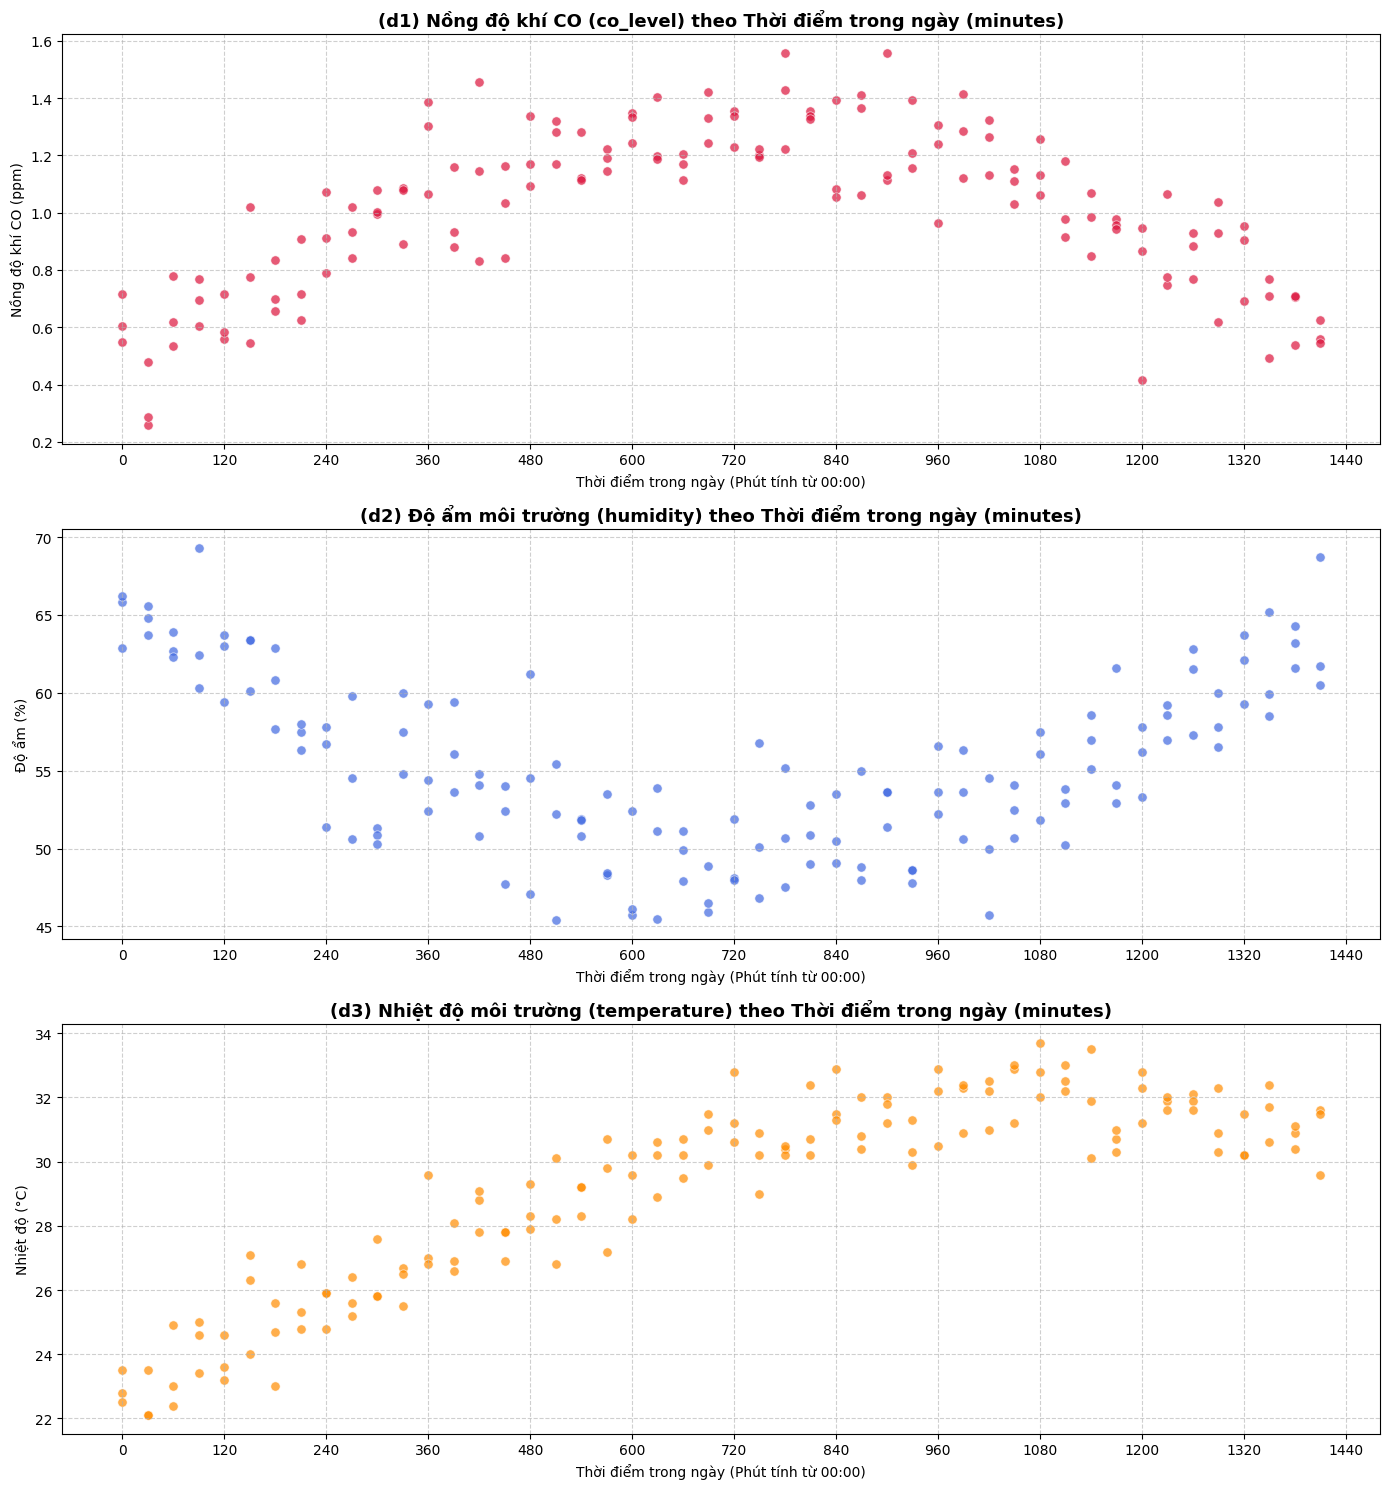

In [4]:
print("Vi Duy Đoàn - 6451071020")
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(14, 15))

# 1. Đồ thị phân tán biểu diễn nồng độ khí CO (co_level) theo minutes
sns.scatterplot(x='minutes', y='co_level', data=df, ax=axes[0], color='crimson', alpha=0.7, s=45)
axes[0].set_title('(d1) Nồng độ khí CO (co_level) theo Thời điểm trong ngày (minutes)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Thời điểm trong ngày (Phút tính từ 00:00)')
axes[0].set_ylabel('Nồng độ khí CO (ppm)')
axes[0].set_xticks(range(0, 1441, 120))
axes[0].grid(True, linestyle='--', alpha=0.6)

# 2. Đồ thị phân tán biểu diễn độ ẩm (humidity) theo minutes
sns.scatterplot(x='minutes', y='humidity', data=df, ax=axes[1], color='royalblue', alpha=0.7, s=45)
axes[1].set_title('(d2) Độ ẩm môi trường (humidity) theo Thời điểm trong ngày (minutes)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Thời điểm trong ngày (Phút tính từ 00:00)')
axes[1].set_ylabel('Độ ẩm (%)')
axes[1].set_xticks(range(0, 1441, 120))
axes[1].grid(True, linestyle='--', alpha=0.6)

# 3. Đồ thị phân tán biểu diễn nhiệt độ (temperature) theo minutes
sns.scatterplot(x='minutes', y='temperature', data=df, ax=axes[2], color='darkorange', alpha=0.7, s=45)
axes[2].set_title('(d3) Nhiệt độ môi trường (temperature) theo Thời điểm trong ngày (minutes)', fontsize=13, fontweight='bold')
axes[2].set_xlabel('Thời điểm trong ngày (Phút tính từ 00:00)')
axes[2].set_ylabel('Nhiệt độ (°C)')
axes[2].set_xticks(range(0, 1441, 120))
axes[2].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


### Nhận xét Câu 4 (d):
1. **Nồng độ khí CO (`co_level`):**
   - Đồ thị phân tán cho thấy nồng độ khí CO tăng rõ rệt vào các khung giờ hành chính trong ngày (từ khoảng phút 480 đến 1020, tức từ 08:00 sáng đến 17:00 chiều).
   - Đây là thời điểm máy móc, dây chuyền sản xuất và các phương tiện vận tải trong nhà xưởng hoạt động công suất lớn nhất. Vào ban đêm (sau phút 1200, tức 20:00 trở đi), nồng độ CO hạ xuống mức nền an toàn.
2. **Độ ẩm môi trường (`humidity`):**
   - Độ ẩm đạt cực đại vào sáng sớm và ban đêm (phút 0 đến 360, tức 00:00 đến 06:00 sáng) với mức trên 75% - 85%.
   - Khi mặt trời lên và nhiệt độ tăng, độ ẩm giảm sâu, đạt mức thấp nhất vào giữa trưa và đầu giờ chiều (phút 660 đến 840, tức 11:00 đến 14:00).
3. **Nhiệt độ nhà xưởng (`temperature`):**
   - Nhiệt độ có sự tương quan nghịch rõ nét với độ ẩm: Nhiệt độ thấp nhất vào sáng sớm (~24°C - 25°C) và tăng dần đều, đạt đỉnh điểm vào đầu giờ chiều (~32°C - 34°C) do ảnh hưởng kết hợp của bức xạ nhiệt ngoài trời và nhiệt năng tỏa ra từ thiết bị công nghiệp.
4. **Ý nghĩa ứng dụng trong Khai phá dữ liệu:**
   - Việc trực quan hóa các chỉ số môi trường theo trục thời gian trong ngày giúp người quản lý xác định được các ngưỡng giới hạn an toàn lao động, phát hiện các khung giờ có nguy cơ cao về ô nhiễm khí CO hoặc nhiệt độ quá mức, từ đó kích hoạt hệ thống thông gió và làm mát tự động một cách tối ưu.